# Model Evaluation

* Name: Parth Isekar
* Div: E  
* Batch: E1  
* Roll no: 327
* PRN: 202401080062

## Imports and Paths

In [188]:
from pathlib import Path
import json
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, precision_recall_curve, average_precision_score,
                             adjusted_rand_score, normalized_mutual_info_score)

PROJECT_DIR = Path.cwd()
while not (PROJECT_DIR / "models").is_dir():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("Could not locate project models directory")
    PROJECT_DIR = PROJECT_DIR.parent
SPLIT_DIR = PROJECT_DIR / "data" / "train_test"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RAW_DIR = PROJECT_DIR / "data" / "raw"
MODEL_DIR = PROJECT_DIR / "models"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
REPORT_DIR = PROJECT_DIR / "results" / "reports"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
for folder in (METRICS_DIR, REPORT_DIR, PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
SUPERVISED_MODELS = ["ST12000NM0007", "ST4000DM000", "ST8000DM002", "ST8000NM0055", "TOSHIBA MQ01ABF050"]
ALGORITHMS = ["random_forest", "xgboost"]
ISOLATION_MODEL = "ST12000NM0007"
CLUSTER_MODEL_SET = "FOUR_MODEL_SET"


## Load Test Datasets

In [189]:
test_frames = {}
for model_name in SUPERVISED_MODELS:
    test_frames[model_name] = pd.read_csv(SPLIT_DIR / f"{model_name}_test.csv", parse_dates=["date"])
    print(model_name, "test shape:", test_frames[model_name].shape)
isolation_test = pd.read_csv(SPLIT_DIR / f"{ISOLATION_MODEL}_isolation_test.csv", parse_dates=["date"])
print("Isolation Forest test shape:", isolation_test.shape)


ST12000NM0007 test shape: (76462, 24)
ST4000DM000 test shape: (46720, 26)
ST8000DM002 test shape: (19866, 26)
ST8000NM0055 test shape: (29342, 26)
TOSHIBA MQ01ABF050 test shape: (1067, 19)
Isolation Forest test shape: (7652, 24)


## Load Validation Datasets

In [190]:
validation_frames = {}
for model_name in SUPERVISED_MODELS:
    validation_frames[model_name] = pd.read_csv(
        SPLIT_DIR / f"{model_name}_validation.csv", parse_dates=["date"])
    frame = validation_frames[model_name]
    print(model_name, "validation shape:", frame.shape,
          "labels:", frame.failure.value_counts().sort_index().to_dict())
print("The source RF fits on train + validation; held-out validation metrics below are for XGBoost only.")

ST12000NM0007 validation shape: (76462, 24) labels: {0: 74212, 1: 2250}
ST4000DM000 validation shape: (46720, 26) labels: {0: 45926, 1: 794}
ST8000DM002 validation shape: (19866, 26) labels: {0: 19627, 1: 239}
ST8000NM0055 validation shape: (29342, 26) labels: {0: 28906, 1: 436}
TOSHIBA MQ01ABF050 validation shape: (1067, 19) labels: {0: 912, 1: 155}
The source RF fits on train + validation; held-out validation metrics below are for XGBoost only.


## Test Data Inspection

In [191]:
test_summary = []
for model_name, frame in test_frames.items():
    test_summary.append({"model": model_name, "dataset": "last 10 observations",
                         "rows": len(frame), "healthy": int((frame.failure == 0).sum()),
                         "failed": int((frame.failure == 1).sum()),
                         "date_start": frame.date.min(), "date_end": frame.date.max()})
test_summary.append({"model": ISOLATION_MODEL, "dataset": "last-day source experiment",
                     "rows": len(isolation_test), "healthy": int((isolation_test.failure == 0).sum()),
                     "failed": int((isolation_test.failure == 1).sum()),
                     "date_start": isolation_test.date.min(), "date_end": isolation_test.date.max()})
test_summary = pd.DataFrame(test_summary)
display(test_summary)


,model,dataset,rows,healthy,failed,date_start,date_end
0,ST12000NM0007,last 10 observations,76462,74212,2250,2019-10-27,2019-12-31
1,ST4000DM000,last 10 observations,46720,45926,794,2019-10-30,2019-12-31
2,ST8000DM002,last 10 observations,19866,19627,239,2019-10-22,2019-12-31
3,ST8000NM0055,last 10 observations,29342,28906,436,2019-10-15,2019-12-31
4,TOSHIBA MQ01ABF050,last 10 observations,1067,912,155,2019-11-02,2019-12-31
5,ST12000NM0007,last-day source experiment,7652,7425,227,2019-11-01,2019-12-31


## Validation Data Inspection

In [192]:
validation_summary = []
for model_name, frame in validation_frames.items():
    validation_summary.append({"model": model_name, "rows": len(frame),
                              "healthy": int((frame.failure == 0).sum()),
                              "failed": int((frame.failure == 1).sum()),
                              "date_start": frame.date.min(), "date_end": frame.date.max()})
validation_summary = pd.DataFrame(validation_summary)
display(validation_summary)

,model,rows,healthy,failed,date_start,date_end
0,ST12000NM0007,76462,74212,2250,2019-09-04,2019-12-29
1,ST4000DM000,46720,45926,794,2019-08-15,2019-12-29
2,ST8000DM002,19866,19627,239,2019-08-29,2019-12-29
3,ST8000NM0055,29342,28906,436,2019-07-13,2019-12-29
4,TOSHIBA MQ01ABF050,1067,912,155,2019-08-20,2019-12-29


## Load Saved Models

In [193]:
def artifact_path(model_name, algorithm):
    if model_name == CLUSTER_MODEL_SET:
        return MODEL_DIR / f"model_identification_{algorithm}.joblib"
    return MODEL_DIR / f"{model_name}_{algorithm}.joblib"

expected_keys = [(m, a) for m in SUPERVISED_MODELS for a in ALGORITHMS]
expected_keys += [(ISOLATION_MODEL, "isolation_forest"),
                  (CLUSTER_MODEL_SET, "kmeans")]
loaded_artifacts = {}
for key in expected_keys:
    path = artifact_path(*key)
    if not path.is_file():
        raise FileNotFoundError(f"Missing model artifact: {path}. Run Notebook 03 with TRAIN=True first.")
    print("Loading", key, "from", path.name)
    loaded_artifacts[key] = joblib.load(path)


Loading ('ST12000NM0007', 'random_forest') from ST12000NM0007_random_forest.joblib
Loading ('ST12000NM0007', 'xgboost') from ST12000NM0007_xgboost.joblib
Loading ('ST4000DM000', 'random_forest') from ST4000DM000_random_forest.joblib
Loading ('ST4000DM000', 'xgboost') from ST4000DM000_xgboost.joblib
Loading ('ST8000DM002', 'random_forest') from ST8000DM002_random_forest.joblib
Loading ('ST8000DM002', 'xgboost') from ST8000DM002_xgboost.joblib
Loading ('ST8000NM0055', 'random_forest') from ST8000NM0055_random_forest.joblib
Loading ('ST8000NM0055', 'xgboost') from ST8000NM0055_xgboost.joblib
Loading ('TOSHIBA MQ01ABF050', 'random_forest') from TOSHIBA MQ01ABF050_random_forest.joblib
Loading ('TOSHIBA MQ01ABF050', 'xgboost') from TOSHIBA MQ01ABF050_xgboost.joblib
Loading ('ST12000NM0007', 'isolation_forest') from ST12000NM0007_isolation_forest.joblib
Loading ('FOUR_MODEL_SET', 'kmeans') from model_identification_kmeans.joblib


## Artifact Metadata and Feature Columns

In [194]:
artifact_rows = []
for (model_name, algorithm), artifact in loaded_artifacts.items():
    estimator = artifact["model"]
    artifact_rows.append({"model": model_name, "algorithm": algorithm,
                          "feature_count": len(artifact["features"]),
                          "features": artifact["features"],
                          "fitted_feature_count": getattr(estimator, "n_features_in_", None),
                          "training_split": artifact["training_split"],
                          "sampling": artifact["sampling"]})
artifact_metadata = pd.DataFrame(artifact_rows)
display(artifact_metadata)


,model,algorithm,feature_count,features,fitted_feature_count,training_split,sampling
0,ST12000NM0007,random_forest,19,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",19,"first 80% per label class, chronological",resample complete failure class to healthy tra...
1,ST12000NM0007,xgboost,19,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",19,"first 60% per label class, chronological; next...",resample complete failure class to healthy tra...
2,ST4000DM000,random_forest,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 80% per label class, chronological",resample complete failure class to healthy tra...
3,ST4000DM000,xgboost,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 60% per label class, chronological; next...",resample complete failure class to healthy tra...
4,ST8000DM002,random_forest,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 80% per label class, chronological",resample complete failure class to healthy tra...
5,ST8000DM002,xgboost,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 60% per label class, chronological; next...",resample complete failure class to healthy tra...
6,ST8000NM0055,random_forest,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 80% per label class, chronological",resample complete failure class to healthy tra...
7,ST8000NM0055,xgboost,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_...",21,"first 60% per label class, chronological; next...",resample complete failure class to healthy tra...
8,TOSHIBA MQ01ABF050,random_forest,14,"[smart_3_raw, smart_4_raw, smart_5_raw, smart_...",14,"first 80% per label class, chronological",resample complete failure class to healthy tra...
9,TOSHIBA MQ01ABF050,xgboost,14,"[smart_3_raw, smart_4_raw, smart_5_raw, smart_...",14,"first 60% per label class, chronological; next...",resample complete failure class to healthy tra...


## Generate Predictions and Scores

In [195]:
prediction_results = {}
for model_name in SUPERVISED_MODELS:
    test = test_frames[model_name]
    for algorithm in ALGORITHMS:
        artifact = loaded_artifacts[(model_name, algorithm)]
        model = artifact["model"]
        features = artifact["features"]
        missing = sorted(set(features) - set(test.columns))
        if missing:
            raise ValueError(f"{model_name}/{algorithm} test data lacks features: {missing}")
        y_pred = model.predict(test[features])
        y_score = model.predict_proba(test[features])[:, 1]
        prediction_results[(model_name, algorithm)] = {
            "actual": test["failure"].to_numpy(), "predicted": np.asarray(y_pred),
            "score": np.asarray(y_score), "score_type": "predict_proba positive-class probability",
            "identifiers": test[[c for c in ("date", "serial_number") if c in test]].reset_index(drop=True)
        }
        print(f"Predictions generated: {model_name} / {algorithm}; {len(y_pred)} rows")


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s


Predictions generated: ST12000NM0007 / random_forest; 76462 rows
Predictions generated: ST12000NM0007 / xgboost; 76462 rows


[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


Predictions generated: ST4000DM000 / random_forest; 46720 rows
Predictions generated: ST4000DM000 / xgboost; 46720 rows
Predictions generated: ST8000DM002 / random_forest; 19866 rows
Predictions generated: ST8000DM002 / xgboost; 19866 rows


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished


Predictions generated: ST8000NM0055 / random_forest; 29342 rows
Predictions generated: ST8000NM0055 / xgboost; 29342 rows
Predictions generated: TOSHIBA MQ01ABF050 / random_forest; 1067 rows
Predictions generated: TOSHIBA MQ01ABF050 / xgboost; 1067 rows


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


In [196]:
artifact = loaded_artifacts[(ISOLATION_MODEL, "isolation_forest")]
isolation_features = artifact["features"]
missing_isolation = sorted(set(isolation_features) - set(isolation_test.columns))
if missing_isolation:
    raise ValueError(f"Isolation Forest test data lacks features: {missing_isolation}")
isolation_estimator = artifact["model"]
isolation_raw_prediction = isolation_estimator.predict(isolation_test[isolation_features])
isolation_score = -isolation_estimator.decision_function(isolation_test[isolation_features])
prediction_results[(ISOLATION_MODEL, "isolation_forest")] = {
    "actual": isolation_test["failure"].to_numpy(),
    "predicted": np.where(isolation_raw_prediction < 0, 1, 0),
    "score": np.asarray(isolation_score),
    "score_type": "negative decision_function (higher means more anomalous)",
    "identifiers": isolation_test[["date", "serial_number"]].reset_index(drop=True)
}
print("Isolation Forest predictions generated; score is not a probability.")


Isolation Forest predictions generated; score is not a probability.


## XGBoost Validation Predictions

In [197]:
validation_results = {}
for model_name in SUPERVISED_MODELS:
    validation = validation_frames[model_name]
    artifact = loaded_artifacts[(model_name, "xgboost")]
    features = artifact["features"]
    missing = sorted(set(features) - set(validation.columns))
    if missing:
        raise ValueError(f"{model_name}/xgboost validation data lacks features: {missing}")
    model = artifact["model"]
    y_pred = model.predict(validation[features])
    y_score = model.predict_proba(validation[features])[:, 1]
    validation_results[(model_name, "xgboost")] = {
        "actual": validation["failure"].to_numpy(), "predicted": np.asarray(y_pred),
        "score": np.asarray(y_score), "score_type": "predict_proba positive-class probability",
        "identifiers": validation[[c for c in ("date", "serial_number") if c in validation]].reset_index(drop=True)
    }
    print(f"Validation predictions generated: {model_name} / xgboost; {len(y_pred)} rows")

Validation predictions generated: ST12000NM0007 / xgboost; 76462 rows
Validation predictions generated: ST4000DM000 / xgboost; 46720 rows
Validation predictions generated: ST8000DM002 / xgboost; 19866 rows
Validation predictions generated: ST8000NM0055 / xgboost; 29342 rows
Validation predictions generated: TOSHIBA MQ01ABF050 / xgboost; 1067 rows


## Actual and Predicted Samples

In [198]:
for (model_name, algorithm), result in prediction_results.items():
    sample = result["identifiers"].head(5).copy()
    sample["actual"] = result["actual"][:5]
    sample["predicted"] = result["predicted"][:5]
    sample["score"] = result["score"][:5]
    print(f"{model_name} / {algorithm}")
    display(sample)


ST12000NM0007 / random_forest


,date,serial_number,actual,predicted,score
0,2019-12-29,ZJV02SF7,0,0,0.000084
1,2019-12-29,ZCH0BPLH,0,0,0.000000
2,2019-12-29,ZJV02PFM,0,0,0.039448
3,2019-12-29,ZJV01WQM,0,0,0.000000
4,2019-12-29,ZJV02PDP,0,0,0.006373


ST12000NM0007 / xgboost


,date,serial_number,actual,predicted,score
0,2019-12-29,ZJV02SF7,0,0,0.020342
1,2019-12-29,ZCH0BPLH,0,0,0.003301
2,2019-12-29,ZJV02PFM,0,1,0.500402
3,2019-12-29,ZJV01WQM,0,0,0.017966
4,2019-12-29,ZJV02PDP,0,0,0.198291


ST4000DM000 / random_forest


,date,serial_number,actual,predicted,score
0,2019-12-29,Z302AHWL,0,0,0.000000
1,2019-12-29,Z304J9QV,0,0,0.000000
2,2019-12-29,Z304J9R3,0,0,0.000108
3,2019-12-29,Z304JKRQ,0,0,0.000000
4,2019-12-29,Z3029Z92,0,0,0.000000


... (12 outputs left out)

TOSHIBA MQ01ABF050 / xgboost


,date,serial_number,actual,predicted,score
0,2019-12-29,66HLS2OIS,0,0,0.002926
1,2019-12-29,96ICTBQHT,0,0,0.006678
2,2019-12-29,57GGPDA2T,0,0,0.064984
3,2019-12-29,66GHS5M9S,0,0,0.001804
4,2019-12-29,57RFWNHNT,0,0,0.000398


ST12000NM0007 / isolation_forest


,date,serial_number,actual,predicted,score
0,2019-12-31,ZCH0CQ0B,0,0,-0.039547
1,2019-12-31,ZCH0CQ0J,0,0,-0.024198
2,2019-12-31,ZCH0CQ29,0,1,0.018411
3,2019-12-31,ZCH0CQB4,0,0,-0.027083
4,2019-12-31,ZCH0CQBA,0,0,-0.012732


## Classification Metrics

In [199]:
metric_rows = []
report_objects = {}
for (model_name, algorithm), result in prediction_results.items():
    y_true = result["actual"]
    y_pred = result["predicted"]
    y_score = result["score"]
    metric_rows.append({"model": model_name, "algorithm": algorithm,
                        "dataset": "last-day" if algorithm == "isolation_forest" else "last-10-observations",
                        "accuracy": accuracy_score(y_true, y_pred),
                        "precision": precision_score(y_true, y_pred, zero_division=0),
                        "recall": recall_score(y_true, y_pred, zero_division=0),
                        "f1": f1_score(y_true, y_pred, zero_division=0),
                        "roc_auc": roc_auc_score(y_true, y_score),
                        "average_precision": average_precision_score(y_true, y_score),
                        "support": len(y_true), "score_type": result["score_type"]})
    report_objects[f"{model_name}::{algorithm}"] = classification_report(
        y_true, y_pred, output_dict=True, zero_division=0)
metrics_table = pd.DataFrame(metric_rows)
display(metrics_table)


,model,algorithm,dataset,accuracy,precision,recall,f1,roc_auc,average_precision,support,score_type
0,ST12000NM0007,random_forest,last-10-observations,0.999359,0.978686,1.000000,0.989228,1.000000,1.000000,76462,predict_proba positive-class probability
1,ST12000NM0007,xgboost,last-10-observations,0.957417,0.407024,0.978667,0.574935,0.995397,0.907513,76462,predict_proba positive-class probability
2,ST4000DM000,random_forest,last-10-observations,0.999936,0.996236,1.000000,0.998114,1.000000,1.000000,46720,predict_proba positive-class probability
3,ST4000DM000,xgboost,last-10-observations,0.976263,0.417236,1.000000,0.588802,0.998721,0.930524,46720,predict_proba positive-class probability
4,ST8000DM002,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19866,predict_proba positive-class probability
5,ST8000DM002,xgboost,last-10-observations,0.999044,0.926357,1.000000,0.961771,1.000000,1.000000,19866,predict_proba positive-class probability
6,ST8000NM0055,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,29342,predict_proba positive-class probability
7,ST8000NM0055,xgboost,last-10-observations,0.999387,0.960352,1.000000,0.979775,1.000000,1.000000,29342,predict_proba positive-class probability
8,TOSHIBA MQ01ABF050,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1067,predict_proba positive-class probability
9,TOSHIBA MQ01ABF050,xgboost,last-10-observations,0.998126,0.987261,1.000000,0.993590,1.000000,1.000000,1067,predict_proba positive-class probability


## Validation Metrics

In [200]:
validation_metric_rows = []
validation_report_objects = {}
for (model_name, algorithm), result in validation_results.items():
    y_true = result["actual"]
    y_pred = result["predicted"]
    y_score = result["score"]
    validation_metric_rows.append({"model": model_name, "algorithm": algorithm,
                                   "dataset": "validation",
                                   "accuracy": accuracy_score(y_true, y_pred),
                                   "precision": precision_score(y_true, y_pred, zero_division=0),
                                   "recall": recall_score(y_true, y_pred, zero_division=0),
                                   "f1": f1_score(y_true, y_pred, zero_division=0),
                                   "roc_auc": roc_auc_score(y_true, y_score),
                                   "average_precision": average_precision_score(y_true, y_score),
                                   "support": len(y_true), "score_type": result["score_type"]})
    validation_report_objects[f"{model_name}::{algorithm}"] = classification_report(
        y_true, y_pred, output_dict=True, zero_division=0)
validation_metrics_table = pd.DataFrame(validation_metric_rows)
display(validation_metrics_table)

,model,algorithm,dataset,accuracy,precision,recall,f1,roc_auc,average_precision,support,score_type
0,ST12000NM0007,xgboost,validation,0.977204,0.564064,0.992,0.719188,0.998334,0.959847,76462,predict_proba positive-class probability
1,ST4000DM000,xgboost,validation,0.989812,0.625197,1.000,0.769380,0.999778,0.987788,46720,predict_proba positive-class probability
2,ST8000DM002,xgboost,validation,0.999849,0.987603,1.000,0.993763,1.000000,1.000000,19866,predict_proba positive-class probability
3,ST8000NM0055,xgboost,validation,0.999625,0.975391,1.000,0.987542,1.000000,1.000000,29342,predict_proba positive-class probability
4,TOSHIBA MQ01ABF050,xgboost,validation,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1067,predict_proba positive-class probability


## XGBoost Validation Threshold Diagnostics

Show how precision, recall, and F1 change across thresholds using validation probabilities. This is diagnostic only: it does not select a new threshold or change the model predictions used in the test metrics.

In [201]:
threshold_values = np.round(np.arange(0.01, 1.00, 0.01), 2)
threshold_rows = []
for (model_name, algorithm), result in validation_results.items():
    actual = result["actual"]
    scores = result["score"]
    for threshold in threshold_values:
        predicted = (scores >= threshold).astype(int)
        threshold_rows.append({"model": model_name, "algorithm": algorithm,
                               "threshold": threshold,
                               "precision": precision_score(actual, predicted, zero_division=0),
                               "recall": recall_score(actual, predicted, zero_division=0),
                               "f1": f1_score(actual, predicted, zero_division=0)})
threshold_metrics = pd.DataFrame(threshold_rows)
display(threshold_metrics[threshold_metrics.threshold.isin([0.1, 0.25, 0.5, 0.75, 0.9])]
        .sort_values(["model", "threshold"]).reset_index(drop=True))

,model,algorithm,threshold,precision,recall,f1
0,ST12000NM0007,xgboost,0.10,0.125642,1.000000,0.223236
1,ST12000NM0007,xgboost,0.25,0.283835,0.997333,0.441906
2,ST12000NM0007,xgboost,0.50,0.564064,0.992000,0.719188
3,ST12000NM0007,xgboost,0.75,0.797378,0.946222,0.865447
4,ST12000NM0007,xgboost,0.90,0.922708,0.854222,0.887145
5,ST4000DM000,xgboost,0.10,0.185731,1.000000,0.313277
6,ST4000DM000,xgboost,0.25,0.376125,1.000000,0.546644
7,ST4000DM000,xgboost,0.50,0.625197,1.000000,0.769380
8,ST4000DM000,xgboost,0.75,0.858242,0.983627,0.916667
9,ST4000DM000,xgboost,0.90,0.966942,0.884131,0.923684


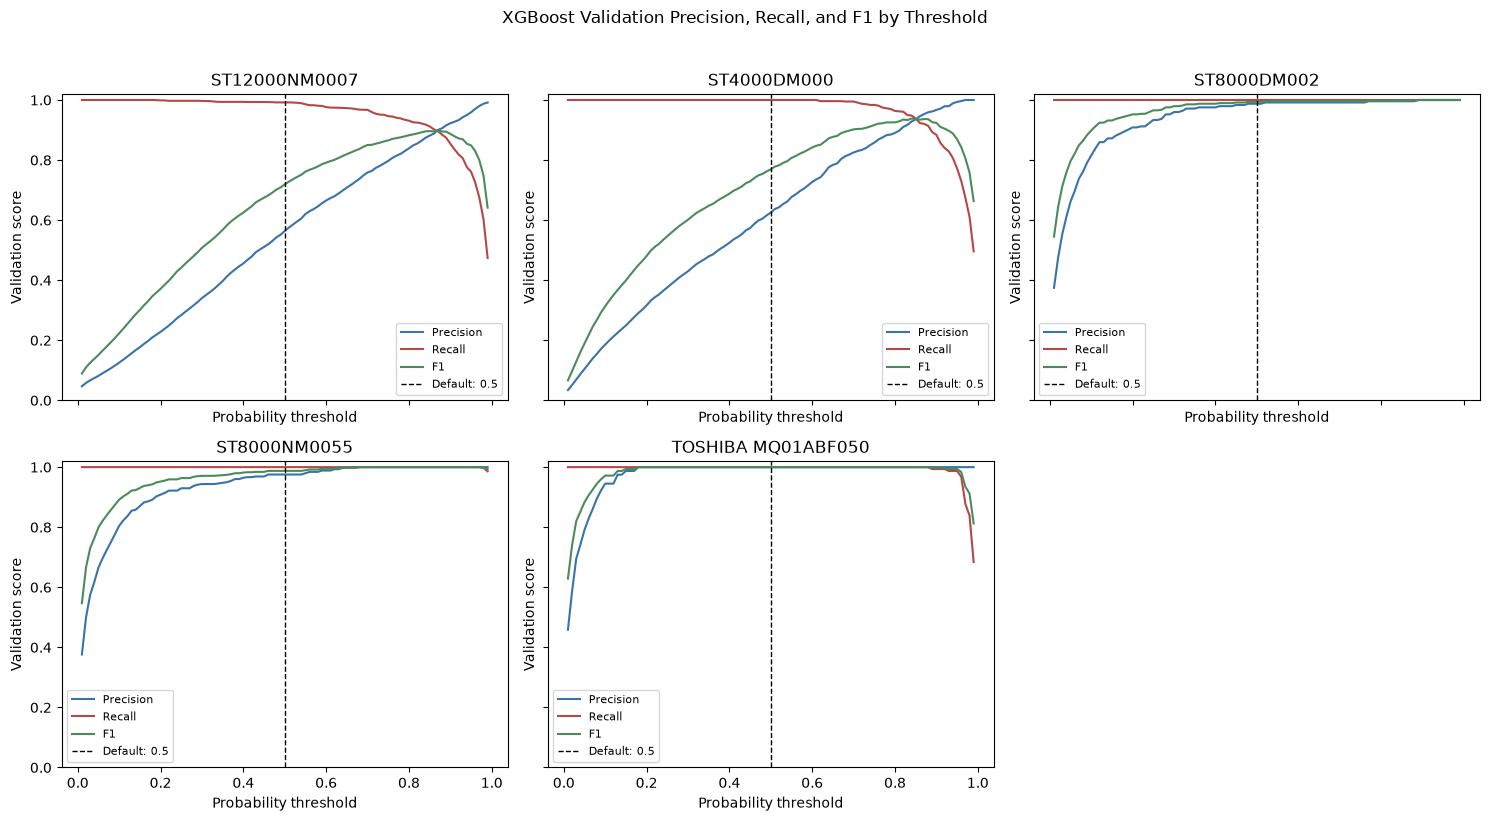

In [202]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, model_name in zip(axes.flat, SUPERVISED_MODELS):
    subset = threshold_metrics[threshold_metrics.model == model_name]
    for metric, color in [("precision", "#3973ac"), ("recall", "#b54747"), ("f1", "#4b8b5a")]:
        ax.plot(subset["threshold"], subset[metric], color=color, label=metric.title())
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default: 0.5")
    ax.set(title=model_name, xlabel="Probability threshold", ylabel="Validation score", ylim=(0, 1.02))
    ax.legend(fontsize=8)
for ax in axes.flat[len(SUPERVISED_MODELS):]:
    ax.set_visible(False)
fig.suptitle("XGBoost Validation Precision, Recall, and F1 by Threshold", y=1.02)
fig.tight_layout()
fig.savefig(PLOT_DIR / "xgboost_validation_threshold_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

## Validation Classification Reports

In [203]:
for key, report in validation_report_objects.items():
    print(key, "validation")
    display(pd.DataFrame(report).T)

ST12000NM0007::xgboost validation


,precision,recall,f1-score,support
0,0.999752,0.976756,0.988120,74212.000000
1,0.564064,0.992000,0.719188,2250.000000
accuracy,0.977204,0.977204,0.977204,0.977204
macro avg,0.781908,0.984378,0.853654,76462.000000
weighted avg,0.986931,0.977204,0.980206,76462.000000


ST4000DM000::xgboost validation


,precision,recall,f1-score,support
0,1.000000,0.989636,0.994791,45926.000000
1,0.625197,1.000000,0.769380,794.000000
accuracy,0.989812,0.989812,0.989812,0.989812
macro avg,0.812598,0.994818,0.882085,46720.000000
weighted avg,0.993630,0.989812,0.990960,46720.000000


ST8000DM002::xgboost validation


,precision,recall,f1-score,support
0,1.000000,0.999847,0.999924,19627.000000
1,0.987603,1.000000,0.993763,239.000000
accuracy,0.999849,0.999849,0.999849,0.999849
macro avg,0.993802,0.999924,0.996843,19866.000000
weighted avg,0.999851,0.999849,0.999849,19866.000000


ST8000NM0055::xgboost validation


,precision,recall,f1-score,support
0,1.000000,0.999619,0.999810,28906.000000
1,0.975391,1.000000,0.987542,436.000000
accuracy,0.999625,0.999625,0.999625,0.999625
macro avg,0.987696,0.999810,0.993676,29342.000000
weighted avg,0.999634,0.999625,0.999627,29342.000000


TOSHIBA MQ01ABF050::xgboost validation


,precision,recall,f1-score,support
0,1.0,1.0,1.0,912.0
1,1.0,1.0,1.0,155.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,1067.0
weighted avg,1.0,1.0,1.0,1067.0


## Classification Reports

In [204]:
for key, report in report_objects.items():
    print(key)
    display(pd.DataFrame(report).T)


ST12000NM0007::random_forest


,precision,recall,f1-score,support
0,1.000000,0.999340,0.999670,74212.000000
1,0.978686,1.000000,0.989228,2250.000000
accuracy,0.999359,0.999359,0.999359,0.999359
macro avg,0.989343,0.999670,0.994449,76462.000000
weighted avg,0.999373,0.999359,0.999363,76462.000000


ST12000NM0007::xgboost


,precision,recall,f1-score,support
0,0.999324,0.956772,0.977586,74212.000000
1,0.407024,0.978667,0.574935,2250.000000
accuracy,0.957417,0.957417,0.957417,0.957417
macro avg,0.703174,0.967720,0.776260,76462.000000
weighted avg,0.981895,0.957417,0.965737,76462.000000


ST4000DM000::random_forest


,precision,recall,f1-score,support
0,1.000000,0.999935,0.999967,45926.000000
1,0.996236,1.000000,0.998114,794.000000
accuracy,0.999936,0.999936,0.999936,0.999936
macro avg,0.998118,0.999967,0.999041,46720.000000
weighted avg,0.999936,0.999936,0.999936,46720.000000


... (12 outputs left out)

TOSHIBA MQ01ABF050::xgboost


,precision,recall,f1-score,support
0,1.000000,0.997807,0.998902,912.000000
1,0.987261,1.000000,0.993590,155.000000
accuracy,0.998126,0.998126,0.998126,0.998126
macro avg,0.993631,0.998904,0.996246,1067.000000
weighted avg,0.998149,0.998126,0.998131,1067.000000


ST12000NM0007::isolation_forest


,precision,recall,f1-score,support
0,0.980453,0.891717,0.933982,7425.000000
1,0.105673,0.418502,0.168739,227.000000
accuracy,0.877679,0.877679,0.877679,0.877679
macro avg,0.543063,0.655110,0.551361,7652.000000
weighted avg,0.954502,0.877679,0.911281,7652.000000


## Confusion Matrices

In [205]:
confusion_matrices = {}
for key, result in prediction_results.items():
    confusion_matrices[key] = confusion_matrix(result["actual"], result["predicted"], labels=[0, 1])
    print(key, "(rows=actual, columns=predicted)")
    display(pd.DataFrame(confusion_matrices[key], index=["actual 0", "actual 1"],
                         columns=["predicted 0", "predicted 1"]))


('ST12000NM0007', 'random_forest') (rows=actual, columns=predicted)


,predicted 0,predicted 1
actual 0,74163,49
actual 1,0,2250


('ST12000NM0007', 'xgboost') (rows=actual, columns=predicted)


,predicted 0,predicted 1
actual 0,71004,3208
actual 1,48,2202


('ST4000DM000', 'random_forest') (rows=actual, columns=predicted)


,predicted 0,predicted 1
actual 0,45923,3
actual 1,0,794


... (12 outputs left out)

('TOSHIBA MQ01ABF050', 'xgboost') (rows=actual, columns=predicted)


,predicted 0,predicted 1
actual 0,910,2
actual 1,0,155


('ST12000NM0007', 'isolation_forest') (rows=actual, columns=predicted)


,predicted 0,predicted 1
actual 0,6621,804
actual 1,132,95


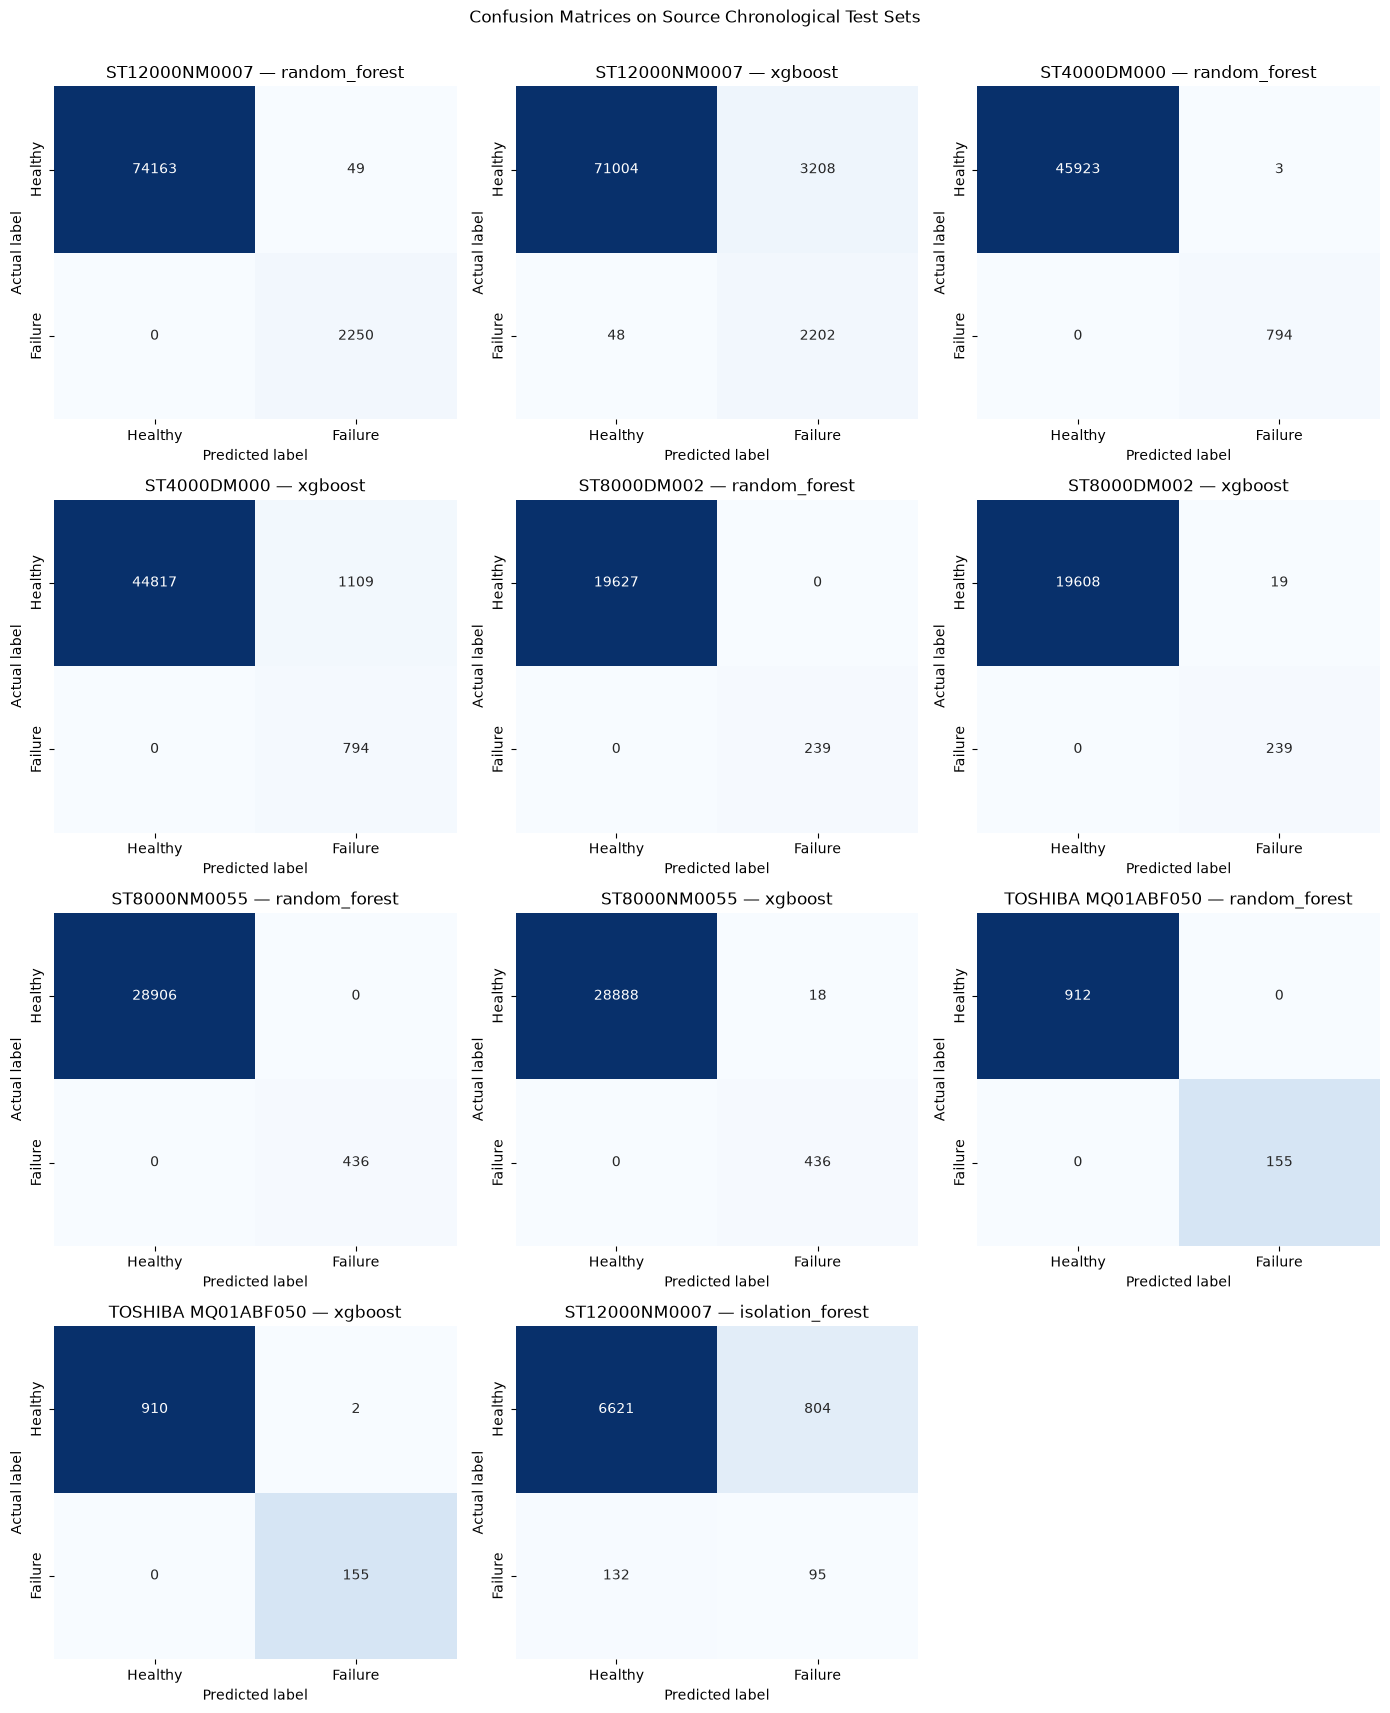

In [206]:
fig, axes = plt.subplots(4, 3, figsize=(14, 17))
for ax, (key, matrix) in zip(axes.flat, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Healthy", "Failure"], yticklabels=["Healthy", "Failure"], ax=ax)
    ax.set(title=f"{key[0]} — {key[1]}", xlabel="Predicted label", ylabel="Actual label")
for ax in axes.flat[len(confusion_matrices):]:
    ax.set_visible(False)
fig.suptitle("Confusion Matrices on Source Chronological Test Sets", y=1.005)
fig.tight_layout()
fig.savefig(PLOT_DIR / "test_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()


## ROC and Precision-Recall Curves

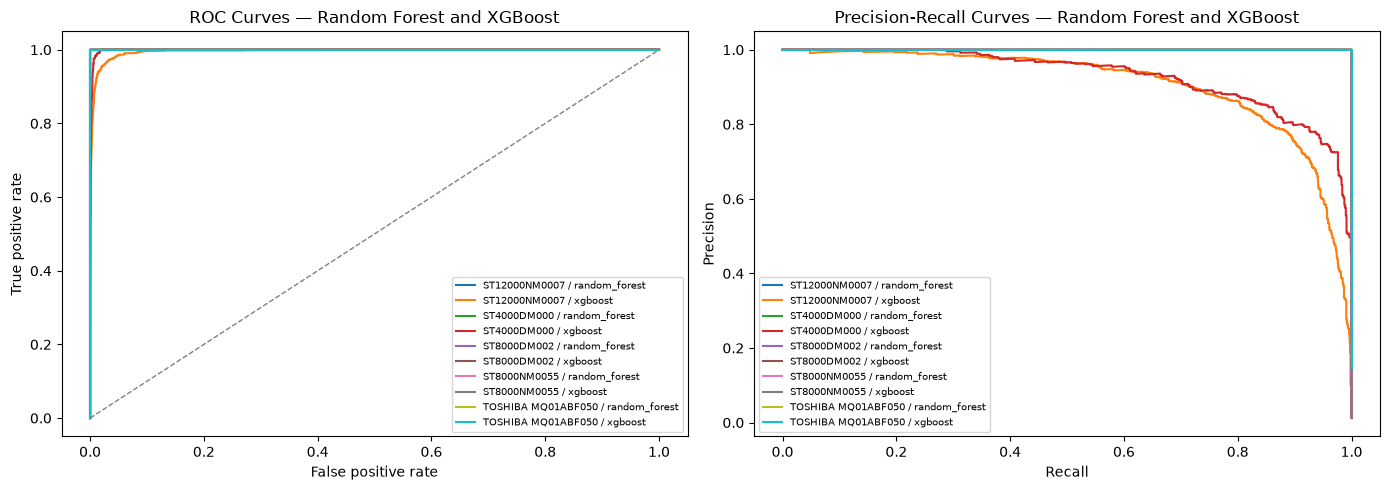

In [207]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name in SUPERVISED_MODELS:
    for algorithm in ALGORITHMS:
        result = prediction_results[(model_name, algorithm)]
        fpr, tpr, _ = roc_curve(result["actual"], result["score"])
        axes[0].plot(fpr, tpr, label=f"{model_name} / {algorithm}")
        precision, recall, _ = precision_recall_curve(result["actual"], result["score"])
        axes[1].plot(recall, precision, label=f"{model_name} / {algorithm}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[0].set(title="ROC Curves — Random Forest and XGBoost", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-Recall Curves — Random Forest and XGBoost", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(PLOT_DIR / "test_roc_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()


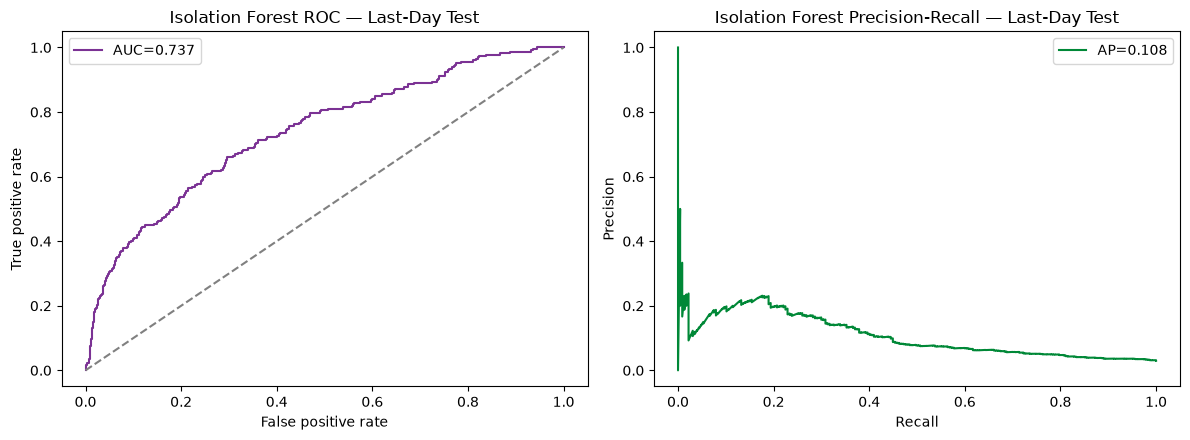

In [208]:
result = prediction_results[(ISOLATION_MODEL, "isolation_forest")]
fpr, tpr, _ = roc_curve(result["actual"], result["score"])
precision, recall, _ = precision_recall_curve(result["actual"], result["score"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#7b3294", label=f"AUC={roc_auc_score(result['actual'], result['score']):.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="Isolation Forest ROC — Last-Day Test", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()
axes[1].plot(recall, precision, color="#008837", label=f"AP={average_precision_score(result['actual'], result['score']):.3f}")
axes[1].set(title="Isolation Forest Precision-Recall — Last-Day Test", xlabel="Recall", ylabel="Precision")
axes[1].legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "isolation_forest_roc_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()


## XGBoost Test Score Distributions

Compare predicted failure probabilities for healthy and failed test rows, separately for each drive. The dashed line marks the estimator’s default 0.5 classification threshold; this plot does not alter predictions.

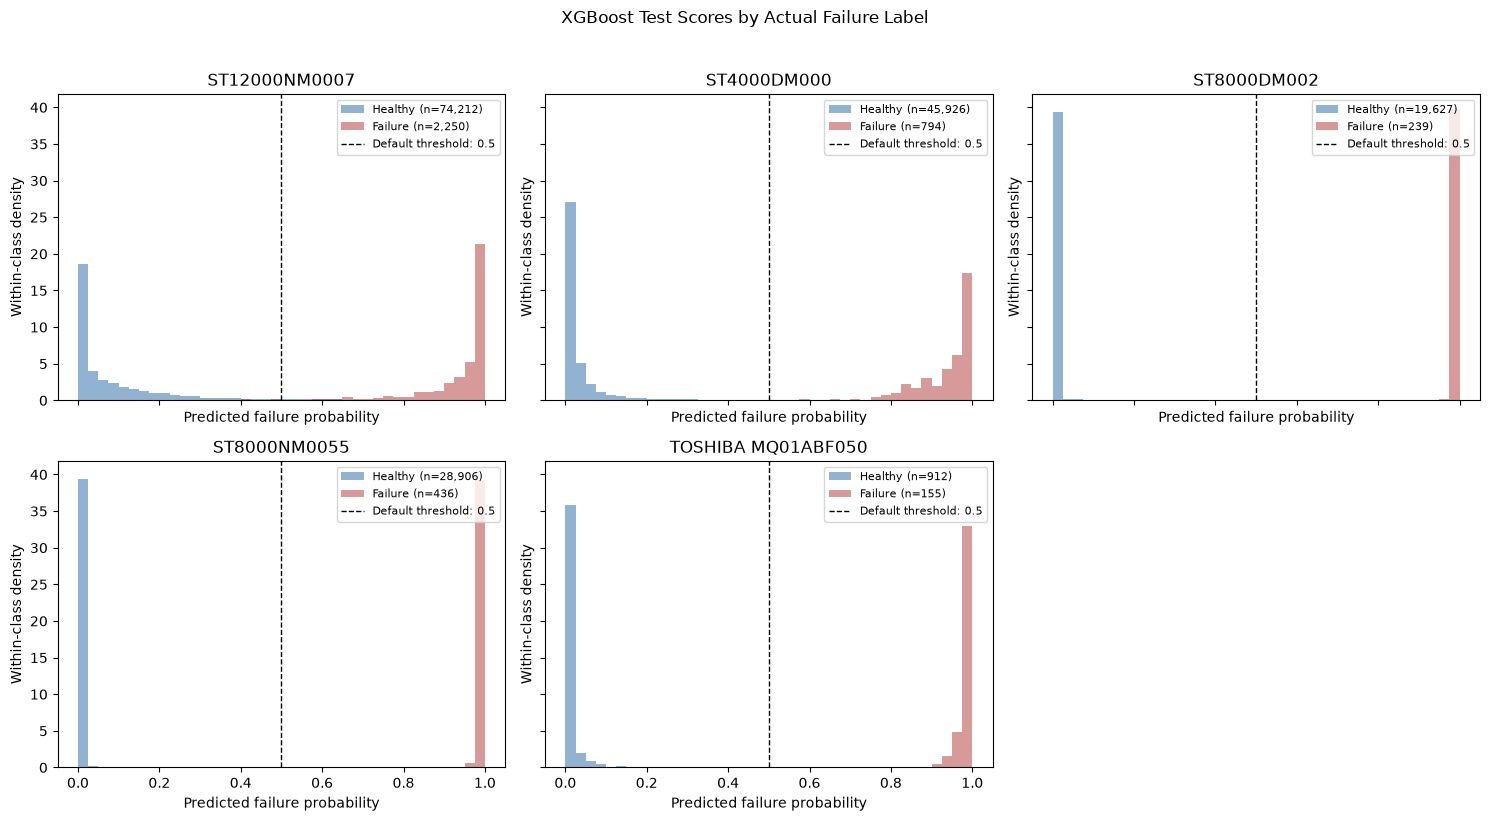

In [209]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
score_bins = np.linspace(0, 1, 41)
for ax, model_name in zip(axes.flat, SUPERVISED_MODELS):
    result = prediction_results[(model_name, "xgboost")]
    actual = result["actual"]
    scores = result["score"]
    for label, name, color in [(0, "Healthy", "#3973ac"), (1, "Failure", "#b54747")]:
        class_scores = scores[actual == label]
        if class_scores.size == 0:
            raise ValueError(f"No {name.lower()} test rows for {model_name}")
        ax.hist(class_scores, bins=score_bins, density=True, alpha=0.55,
                color=color, label=f"{name} (n={class_scores.size:,})")
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default threshold: 0.5")
    ax.set(title=model_name, xlabel="Predicted failure probability", ylabel="Within-class density")
    ax.legend(fontsize=8)
for ax in axes.flat[len(SUPERVISED_MODELS):]:
    ax.set_visible(False)
fig.suptitle("XGBoost Test Scores by Actual Failure Label", y=1.02)
fig.tight_layout()
fig.savefig(PLOT_DIR / "xgboost_test_score_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## Feature Importance

In [210]:
importance_rows = []
importance_support = []
for (model_name, algorithm), artifact in loaded_artifacts.items():
    estimator = artifact["model"]
    if hasattr(estimator, "feature_importances_"):
        for feature, importance in zip(artifact["features"], estimator.feature_importances_):
            importance_rows.append({"model": model_name, "algorithm": algorithm,
                                    "feature": feature, "importance": float(importance)})
        importance_support.append({"model": model_name, "algorithm": algorithm,
                                   "feature_importance": "supported"})
    else:
        importance_support.append({"model": model_name, "algorithm": algorithm,
                                   "feature_importance": "not supported by source estimator"})
feature_importance = pd.DataFrame(importance_rows)
display(pd.DataFrame(importance_support))
display(feature_importance.groupby(["model", "algorithm"], group_keys=False)
        .apply(lambda frame: frame.nlargest(5, "importance"), include_groups=False))


,model,algorithm,feature_importance
0,ST12000NM0007,random_forest,supported
1,ST12000NM0007,xgboost,supported
2,ST4000DM000,random_forest,supported
3,ST4000DM000,xgboost,supported
4,ST8000DM002,random_forest,supported
5,ST8000DM002,xgboost,supported
6,ST8000NM0055,random_forest,supported
7,ST8000NM0055,xgboost,supported
8,TOSHIBA MQ01ABF050,random_forest,supported
9,TOSHIBA MQ01ABF050,xgboost,supported


,feature,importance
2,smart_5_raw,0.212206
16,smart_240_raw,0.133238
4,smart_9_raw,0.116533
17,smart_241_raw,0.106889
10,smart_193_raw,0.090234
21,smart_5_raw,0.408297
25,smart_187_raw,0.148804
32,smart_197_raw,0.091064
37,smart_242_raw,0.060141
35,smart_240_raw,0.049479


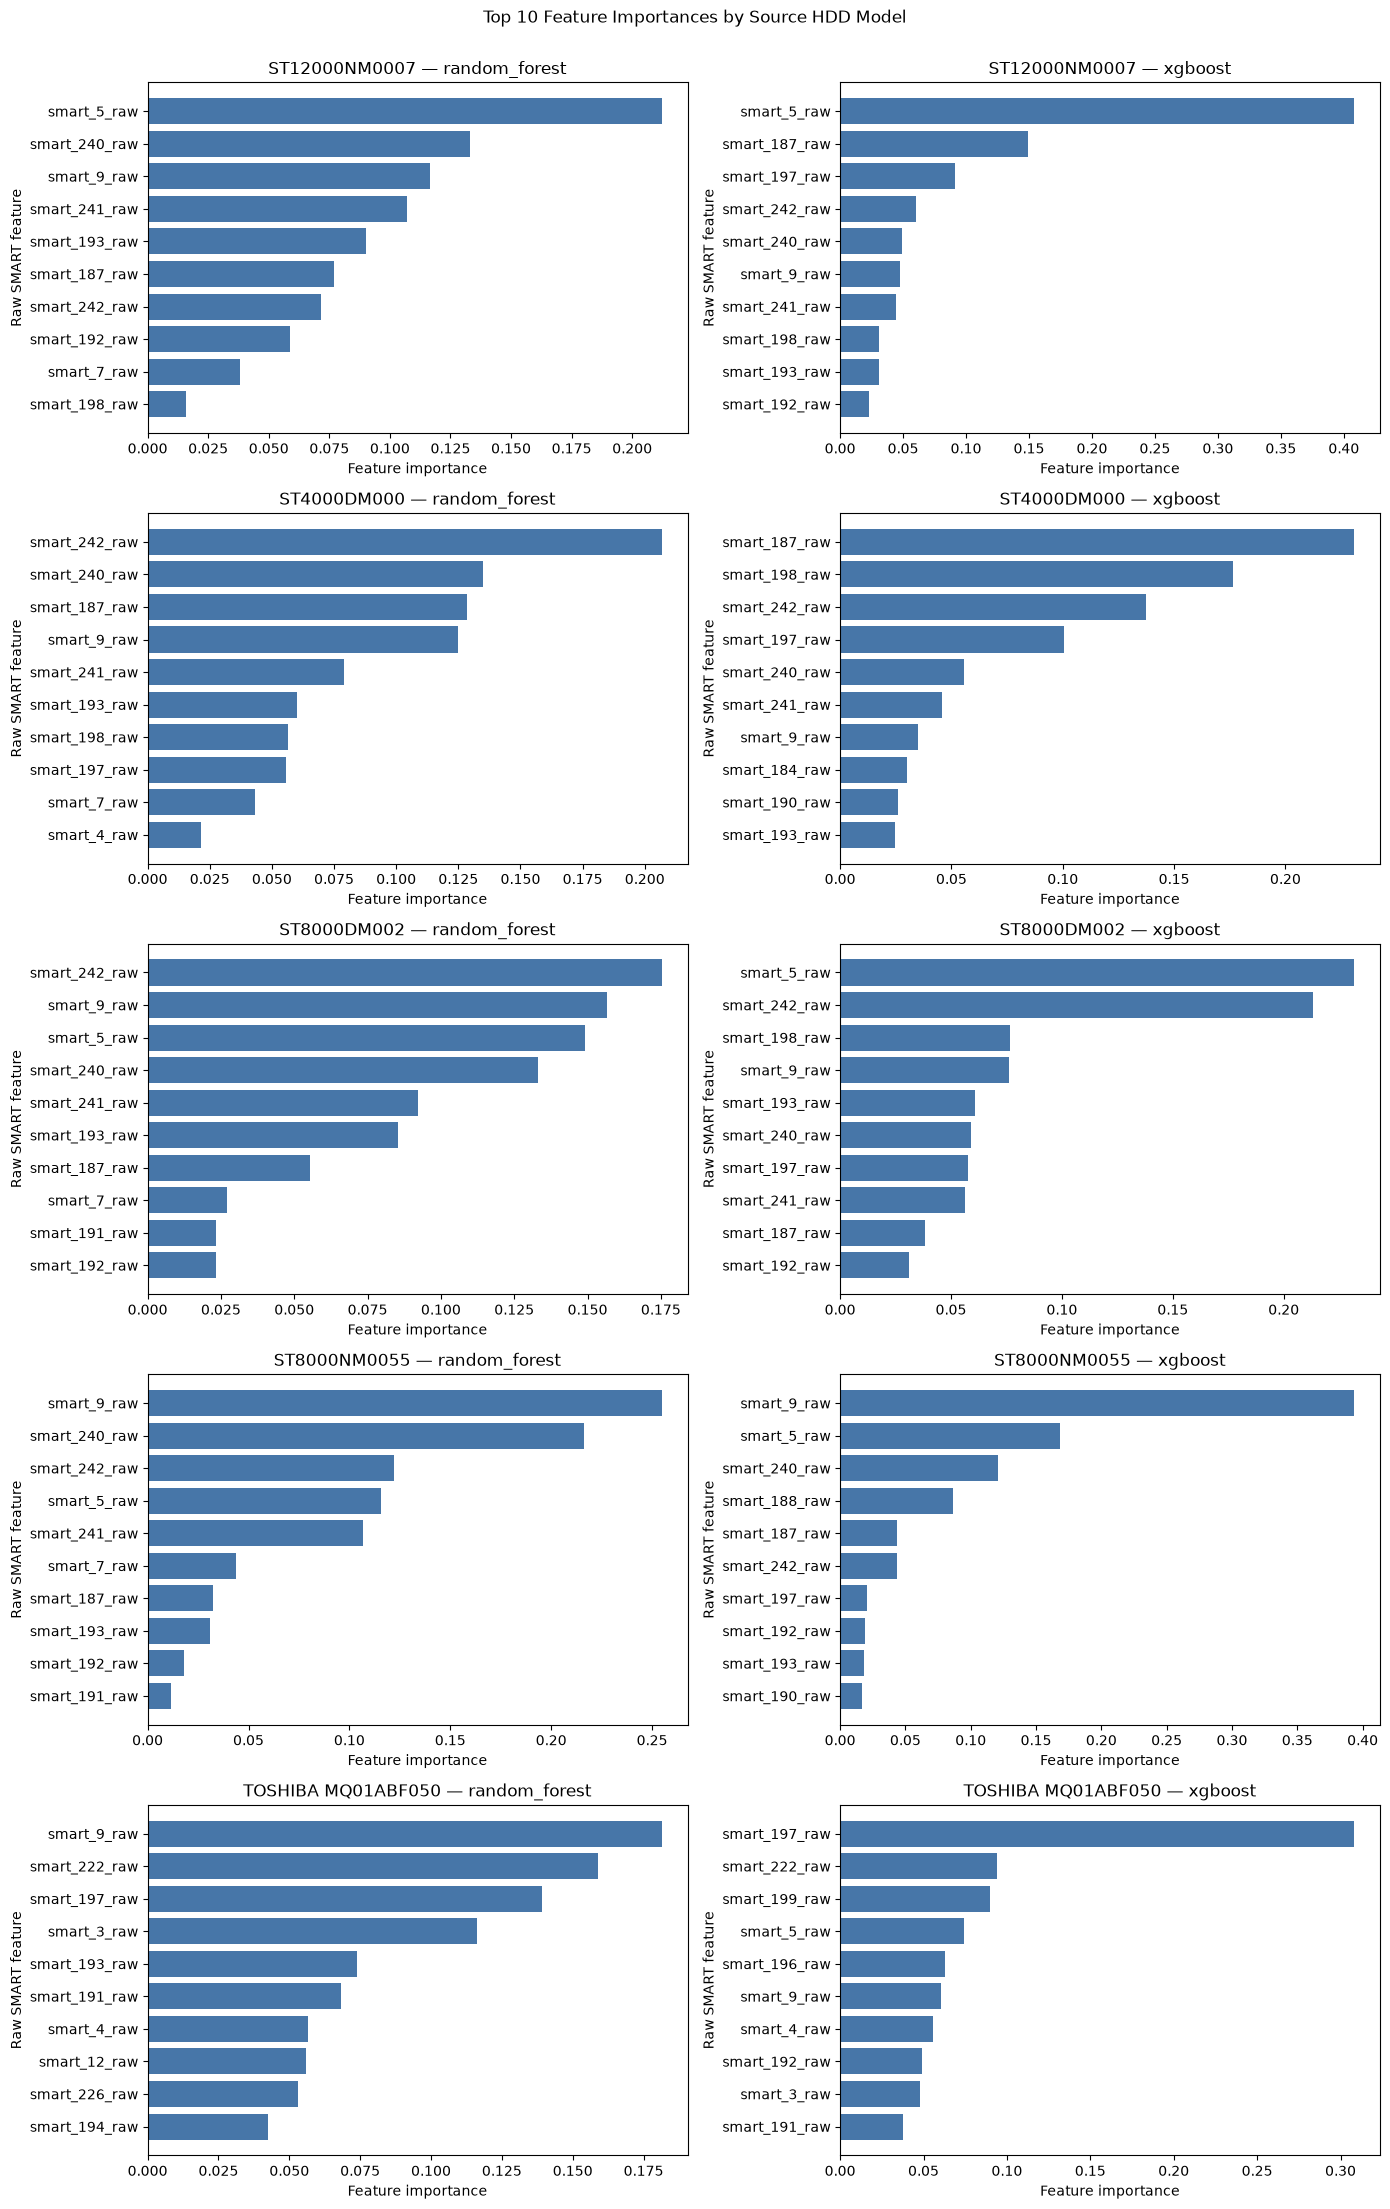

In [211]:
plot_importance = feature_importance[feature_importance["model"].isin(SUPERVISED_MODELS)]
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for row, model_name in enumerate(SUPERVISED_MODELS):
    for column, algorithm in enumerate(ALGORITHMS):
        ax = axes[row, column]
        subset = plot_importance[(plot_importance.model == model_name) & (plot_importance.algorithm == algorithm)]
        subset = subset.nlargest(10, "importance").sort_values("importance")
        ax.barh(subset.feature, subset.importance, color="#4776a8")
        ax.set(title=f"{model_name} — {algorithm}", xlabel="Feature importance", ylabel="Raw SMART feature")
fig.suptitle("Top 10 Feature Importances by Source HDD Model", y=1.002)
fig.tight_layout()
fig.savefig(PLOT_DIR / "test_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()


## Model Comparison

,model,algorithm,dataset,accuracy,precision,recall,f1,roc_auc,average_precision,support,score_type
0,ST12000NM0007,random_forest,last-10-observations,0.999359,0.978686,1.000000,0.989228,1.000000,1.000000,76462,predict_proba positive-class probability
1,ST12000NM0007,xgboost,last-10-observations,0.957417,0.407024,0.978667,0.574935,0.995397,0.907513,76462,predict_proba positive-class probability
2,ST4000DM000,random_forest,last-10-observations,0.999936,0.996236,1.000000,0.998114,1.000000,1.000000,46720,predict_proba positive-class probability
3,ST4000DM000,xgboost,last-10-observations,0.976263,0.417236,1.000000,0.588802,0.998721,0.930524,46720,predict_proba positive-class probability
4,ST8000DM002,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19866,predict_proba positive-class probability
5,ST8000DM002,xgboost,last-10-observations,0.999044,0.926357,1.000000,0.961771,1.000000,1.000000,19866,predict_proba positive-class probability
6,ST8000NM0055,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,29342,predict_proba positive-class probability
7,ST8000NM0055,xgboost,last-10-observations,0.999387,0.960352,1.000000,0.979775,1.000000,1.000000,29342,predict_proba positive-class probability
8,TOSHIBA MQ01ABF050,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1067,predict_proba positive-class probability
9,TOSHIBA MQ01ABF050,xgboost,last-10-observations,0.998126,0.987261,1.000000,0.993590,1.000000,1.000000,1067,predict_proba positive-class probability


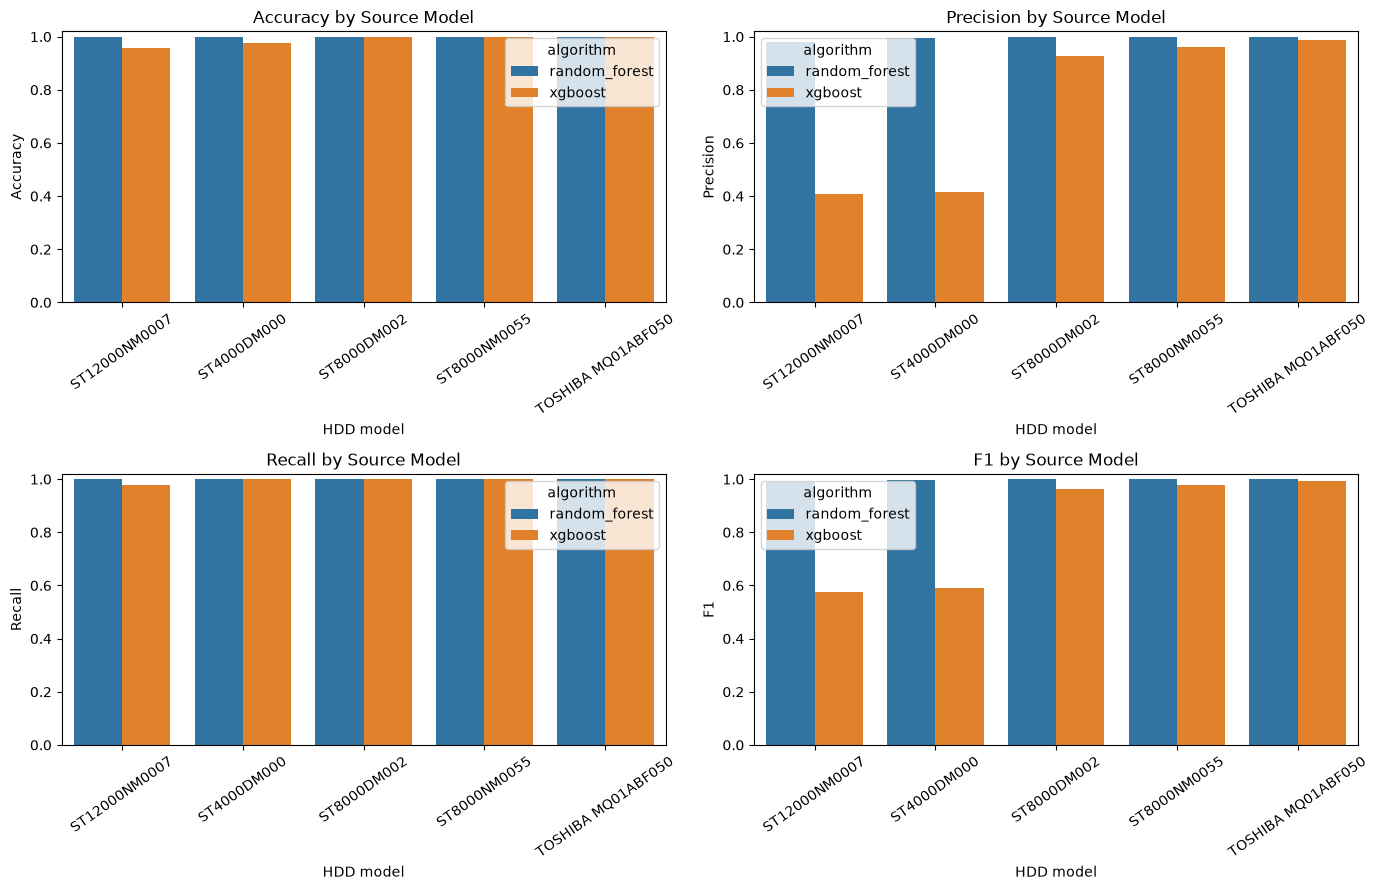

In [212]:
supervised_metrics = metrics_table[metrics_table.algorithm.isin(ALGORITHMS)].copy()
display(supervised_metrics.sort_values(["model", "algorithm"]))
comparison = supervised_metrics.melt(id_vars=["model", "algorithm"],
                                     value_vars=["accuracy", "precision", "recall", "f1"],
                                     var_name="metric", value_name="score")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric in zip(axes.flat, ["accuracy", "precision", "recall", "f1"]):
    sns.barplot(data=comparison[comparison.metric == metric], x="model", y="score",
                hue="algorithm", ax=ax)
    ax.set(title=f"{metric.title()} by Source Model", xlabel="HDD model", ylabel=metric.title())
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(PLOT_DIR / "algorithm_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## Model-Identification Clusters

In [213]:
cluster_data = pd.read_csv(RAW_DIR / "four_model_data.csv", low_memory=False)
cluster_features = ["capacity_bytes", "smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_198_raw"]
cluster_X = cluster_data[cluster_features]
cluster_assignments = {}
kmeans_artifact = loaded_artifacts[(CLUSTER_MODEL_SET, "kmeans")]
cluster_assignments["kmeans"] = kmeans_artifact["model"].predict(cluster_X)
# dbscan_artifact = loaded_artifacts[(CLUSTER_MODEL_SET, "dbscan")]
# cluster_assignments["dbscan"] = dbscan_artifact["model"].labels_
cluster_rows = []
for algorithm, labels in cluster_assignments.items():
    cluster_rows.append({"algorithm": algorithm,
                         "adjusted_rand_index": adjusted_rand_score(cluster_data.model, labels),
                         "normalized_mutual_info": normalized_mutual_info_score(cluster_data.model, labels),
                         "clusters_including_noise": len(np.unique(labels))})
    display(pd.crosstab(cluster_data["model"], labels, rownames=["HDD model"], colnames=[f"{algorithm} cluster"]))
cluster_metrics = pd.DataFrame(cluster_rows)
display(cluster_metrics)


kmeans cluster,0,1,2,3
HDD model,,,,
ST12000NM0007,38207,0,0,49
ST4000DM000,0,0,23394,0
ST8000DM002,0,9936,0,0
ST8000NM0055,0,14679,0,0


,algorithm,adjusted_rand_index,normalized_mutual_info,clusters_including_noise
0,kmeans,0.91061,0.915947,4


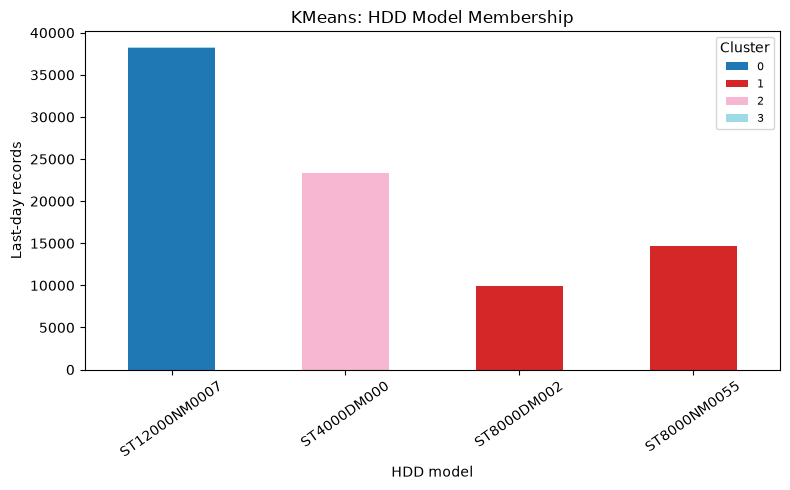

In [214]:
cluster_plot_data = pd.DataFrame({"model": cluster_data["model"],
                                  "kmeans_cluster": cluster_assignments["kmeans"]})
fig, ax = plt.subplots(figsize=(8, 5))
counts = pd.crosstab(cluster_plot_data["model"], cluster_plot_data["kmeans_cluster"])
counts.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
ax.set(title="KMeans: HDD Model Membership", xlabel="HDD model", ylabel="Last-day records")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Cluster", fontsize=8)
fig.tight_layout()
fig.savefig(PLOT_DIR / "model_identification_clusters.png", dpi=160, bbox_inches="tight")
plt.show()

## Save Predictions, Metrics, and Reports

In [215]:
for (model_name, algorithm), result in prediction_results.items():
    prediction_frame = result["identifiers"].copy()
    prediction_frame["actual"] = result["actual"]
    prediction_frame["predicted"] = result["predicted"]
    prediction_frame["score"] = result["score"]
    prediction_frame["score_type"] = result["score_type"]
    prediction_frame.to_csv(METRICS_DIR / f"{model_name}_{algorithm}_test_predictions.csv", index=False)
metrics_table.to_csv(METRICS_DIR / "test_metrics.csv", index=False)
threshold_metrics.to_csv(METRICS_DIR / "xgboost_validation_threshold_metrics.csv", index=False)
feature_importance.to_csv(METRICS_DIR / "feature_importance.csv", index=False)
cluster_metrics.to_csv(METRICS_DIR / "model_identification_cluster_metrics.csv", index=False)
cluster_plot_data.to_csv(METRICS_DIR / "model_identification_cluster_assignments.csv", index=False)
with (REPORT_DIR / "classification_reports.json").open("w", encoding="utf-8") as file:
    json.dump(report_objects, file, indent=2)
print("Predictions saved:", len(prediction_results))
print("Metrics:", METRICS_DIR / "test_metrics.csv")
print("Reports:", REPORT_DIR / "classification_reports.json")


Predictions saved: 11
Metrics: /run/media/yashraj221b/DATA/YASH FILES/Programming/BACKBLAZE_DRIVE/results/metrics/test_metrics.csv
Reports: /run/media/yashraj221b/DATA/YASH FILES/Programming/BACKBLAZE_DRIVE/results/reports/classification_reports.json


## Save Validation Results

In [216]:
validation_prediction_frames = []
for (model_name, algorithm), result in validation_results.items():
    prediction_frame = result["identifiers"].copy()
    prediction_frame["model"] = model_name
    prediction_frame["actual"] = result["actual"]
    prediction_frame["predicted"] = result["predicted"]
    prediction_frame["score"] = result["score"]
    prediction_frame.to_csv(
        METRICS_DIR / f"{model_name}_{algorithm}_validation_predictions.csv", index=False)
    validation_prediction_frames.append(prediction_frame)
pd.concat(validation_prediction_frames, ignore_index=True).to_csv(
    METRICS_DIR / "validation_predictions.csv", index=False)
validation_metrics_table.to_csv(METRICS_DIR / "validation_metrics.csv", index=False)
with (REPORT_DIR / "validation_classification_reports.json").open("w", encoding="utf-8") as file:
    json.dump(validation_report_objects, file, indent=2)
print("Saved XGBoost validation predictions and metrics for", len(validation_results), "drive models")

Saved XGBoost validation predictions and metrics for 5 drive models


## Final Evaluation Results

In [217]:
display(metrics_table.sort_values(["dataset", "model", "algorithm"]).reset_index(drop=True))
print("Plots:")
for path in sorted(PLOT_DIR.glob("*.png")):
    print(path.relative_to(PROJECT_DIR))

print("XGBoost validation metrics")
display(validation_metrics_table.sort_values("model").reset_index(drop=True))

,model,algorithm,dataset,accuracy,precision,recall,f1,roc_auc,average_precision,support,score_type
0,ST12000NM0007,random_forest,last-10-observations,0.999359,0.978686,1.000000,0.989228,1.000000,1.000000,76462,predict_proba positive-class probability
1,ST12000NM0007,xgboost,last-10-observations,0.957417,0.407024,0.978667,0.574935,0.995397,0.907513,76462,predict_proba positive-class probability
2,ST4000DM000,random_forest,last-10-observations,0.999936,0.996236,1.000000,0.998114,1.000000,1.000000,46720,predict_proba positive-class probability
3,ST4000DM000,xgboost,last-10-observations,0.976263,0.417236,1.000000,0.588802,0.998721,0.930524,46720,predict_proba positive-class probability
4,ST8000DM002,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19866,predict_proba positive-class probability
5,ST8000DM002,xgboost,last-10-observations,0.999044,0.926357,1.000000,0.961771,1.000000,1.000000,19866,predict_proba positive-class probability
6,ST8000NM0055,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,29342,predict_proba positive-class probability
7,ST8000NM0055,xgboost,last-10-observations,0.999387,0.960352,1.000000,0.979775,1.000000,1.000000,29342,predict_proba positive-class probability
8,TOSHIBA MQ01ABF050,random_forest,last-10-observations,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1067,predict_proba positive-class probability
9,TOSHIBA MQ01ABF050,xgboost,last-10-observations,0.998126,0.987261,1.000000,0.993590,1.000000,1.000000,1067,predict_proba positive-class probability


Plots:
results/plots/algorithm_comparison.png
results/plots/exploration_core_smart_availability.png
results/plots/exploration_core_smart_nonzero_by_label.png
results/plots/exploration_model_counts_and_failure_rate.png
results/plots/isolation_forest_roc_precision_recall.png
results/plots/model_identification_clusters.png
results/plots/smart_correlation_matrices.png
results/plots/test_confusion_matrices.png
results/plots/test_feature_importance.png
results/plots/test_roc_precision_recall.png
results/plots/xgboost_test_score_distributions.png
results/plots/xgboost_validation_threshold_metrics.png
XGBoost validation metrics


,model,algorithm,dataset,accuracy,precision,recall,f1,roc_auc,average_precision,support,score_type
0,ST12000NM0007,xgboost,validation,0.977204,0.564064,0.992,0.719188,0.998334,0.959847,76462,predict_proba positive-class probability
1,ST4000DM000,xgboost,validation,0.989812,0.625197,1.000,0.769380,0.999778,0.987788,46720,predict_proba positive-class probability
2,ST8000DM002,xgboost,validation,0.999849,0.987603,1.000,0.993763,1.000000,1.000000,19866,predict_proba positive-class probability
3,ST8000NM0055,xgboost,validation,0.999625,0.975391,1.000,0.987542,1.000000,1.000000,29342,predict_proba positive-class probability
4,TOSHIBA MQ01ABF050,xgboost,validation,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1067,predict_proba positive-class probability
